### 1st cell

In [43]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from scipy.interpolate import RegularGridInterpolator

### 2nd PDE, grid and exact solution
Burgers: $u_t + a(u)\,u_x = \alpha u_{xx}$ with $a(u)=u$, on $[0,1]$, $u=0$ at both walls, $u(x,0)=\sin\pi x+\tfrac12\sin2\pi x$, $\alpha=0.1$.
Exact solution by Hopf–Cole: $u=-2\alpha\,\phi_x/\phi$, where $\phi$ solves the heat equation with $\phi_x=0$ at the walls (a cosine series).
The exact solution is only used to check results, never by the agent.

inflow_smooth: alpha = 0.1, T = 0.5 | nx = 50, nt = 276, dx = 0.02041, dt = 1.818e-03 | r = 0.44, nu_max = 0.16, 2r + nu^2 = 0.90
check: FD on a grid 1x finer vs u_true at t = 0.25: max error 1.9e-03
check: FD on a grid 2x finer vs u_true at t = 0.25: max error 4.7e-04
check: FD on a grid 4x finer vs u_true at t = 0.25: max error 1.2e-04


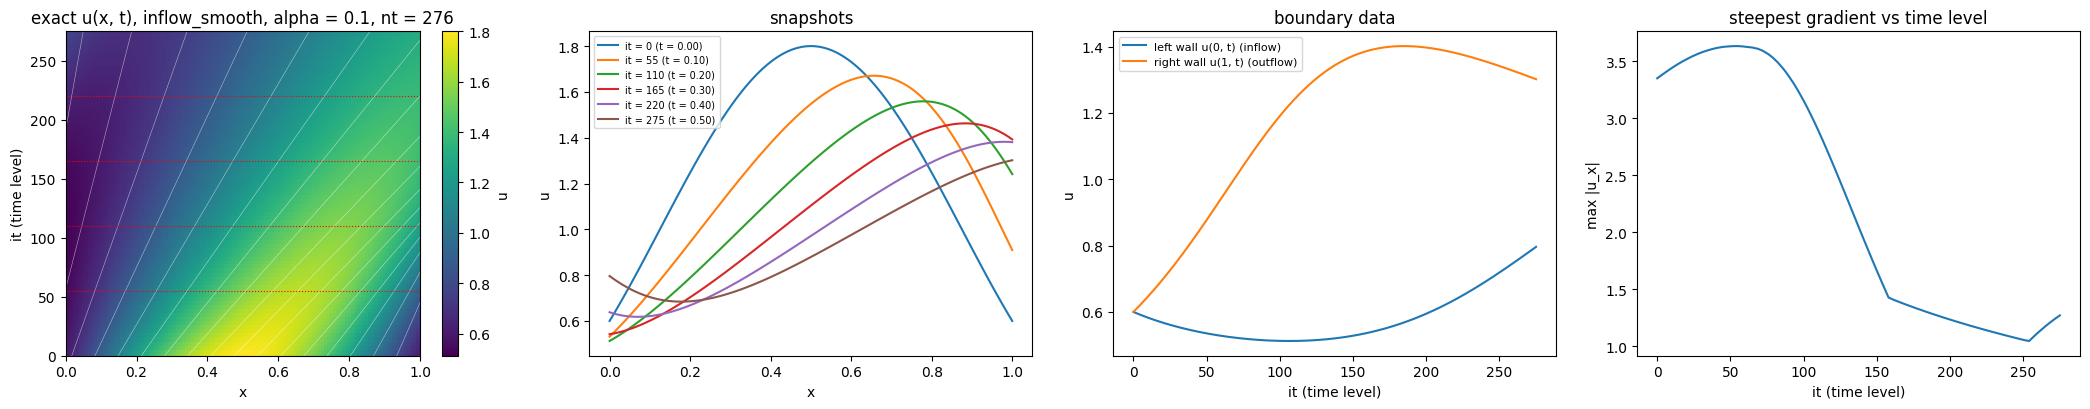

In [44]:
# ── Problem settings: change PROBLEM, everything below follows ──
#   "walls"         : u0 = sin(pi x) + 0.5 sin(2 pi x), u = 0 at both walls, alpha = 0.1   (notebook 12, for comparison)
#   "inflow_smooth" : u0 = 1 + 0.8 sin(2 pi x / 1.5), time-dependent Dirichlet data from the exact solution, alpha = 0.1
#   "inflow_front"  : same, alpha = 0.01: a front forms and leaves (t ~ 0.25-0.35); a second one enters through the left wall (t ~ 0.7)
PROBLEM = "inflow_smooth"   # "walls", "inflow_smooth", or "inflow_front"
alpha, T = {"walls": (0.1, 0.5), "inflow_smooth": (0.1, 0.5), "inflow_front": (0.01, 1.1)}[PROBLEM]

# ── PDE:  u_t + a(u) u_x = alpha u_xx  on [0, 1] ──
a = lambda u: u                                # advection speed: Burgers
if PROBLEM == "walls":
    u0 = lambda x: np.sin(np.pi * x) + 0.5 * np.sin(2 * np.pi * x)
    F0 = lambda x: (1 - np.cos(np.pi * x)) / np.pi + (1 - np.cos(2 * np.pi * x)) / (4 * np.pi)   # integral of u0 from 0
    A_MAX = 1.5                                # bound on |u| (the IC peaks at about 1.26)
else:
    C_BG, A_W, L_W = 1.0, 0.8, 1.5             # background speed, amplitude, wavelength: u stays in [0.2, 1.8] > 0
    X_PK = 0.5                                 # the peak starts at the middle, so u changes a lot there
    u0 = lambda x: C_BG + A_W * np.cos(2 * np.pi * (x - X_PK) / L_W)
    F0 = lambda x: C_BG * x + A_W * L_W / (2 * np.pi) * (np.sin(2 * np.pi * (x - X_PK) / L_W) + np.sin(2 * np.pi * X_PK / L_W))
    A_MAX = C_BG + A_W

# ── Grid ──
# explicit advection + diffusion (LW, FD-3) is stable for 2r + nu^2 <= 1, r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole), as a weighted average so it stays accurate for small alpha ──
#    u(x, t) = sum (x - y)/t W / sum W,   W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),   y on a uniform grid.
#    "walls": F0 mirrored about every wall (even, period 2) -> phi_x = 0 -> u = 0 at x = 0 and 1.
#    inflow : the whole line, no mirrors; the weight peaks near the foot of the characteristic, y ~ x - u t,
#             so the y range reaches A_MAX * T to the left. Both cover 8 kernel widths. Exponents shifted by their max.
_s = 8 * np.sqrt(2 * alpha * T)
if PROBLEM == "walls":
    _lo, _hi = -np.ceil(_s), 1 + np.ceil(_s)
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _yf = np.mod(_Y, 2.0)
    _FY = F0(np.where(_yf > 1, 2 - _yf, _yf)) / (2 * alpha)
else:
    _lo, _hi = -A_MAX * T - _s, 1 + _s
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _FY = F0(_Y) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the grid, one time level at a time when first needed (u_true ONLY for checks, reports, and wall data)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data: u at x = 0 and x = 1 as functions of t (given data, like the IC) ──
# on the grid's time levels it is exact (U_row); between levels (refined classical schemes) a cubic spline through a fine table
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])            # (time, [left, right])
_gs = CubicSpline(_tb, _gb)                                     # cubic in t: accurate enough for high-order schemes too
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"{PROBLEM}: alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

# ── Check: an explicit FD solve (with the same boundary data) on finer grids must converge to u_true (error / 4 per halving) ──
def _fd_fine(k, t_end):
    n, h = (nx - 1) * k + 1, dx / k
    steps = int(np.ceil(t_end / min(0.2 * h**2 / alpha, 0.5 * h / A_MAX))); s = t_end / steps
    u = u0(np.arange(n) * h)
    for j in range(steps):
        u[1:-1] = u[1:-1] + alpha * s / h**2 * (u[2:] - 2 * u[1:-1] + u[:-2]) - u[1:-1] * s / (2 * h) * (u[2:] - u[:-2])
        u[0], u[-1] = g_left((j + 1) * s), g_right((j + 1) * s)
    return u[::k]
_t_chk = 0.5 * T
for k in (1, 2, 4):
    print(f"check: FD on a grid {k}x finer vs u_true at t = {_t_chk:.2f}: max error {np.abs(_fd_fine(k, _t_chk) - u_true(x_grid, _t_chk)).max():.1e}")
# ── Pictures: u(x, t) with characteristics, snapshots, boundary data, steepest gradient (time in levels it = t / dt) ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)               # time levels sampled for the pictures
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u")
if PROBLEM != "walls":                                              # characteristics x = x_0 + u0(x_0) t (inviscid, until they cross)
    for x_0 in np.linspace(-A_MAX * T, 1, 30):
        axes[0].plot(x_0 + u0(x_0) * its * dt, its, "w-", lw=0.4, alpha=0.6)
snap = np.linspace(0, nt - 1, 6).round().astype(int)                # levels of the snapshots, marked on the map
for it in snap:
    axes[0].axhline(it, color="r", ls=":", lw=0.8)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, nt - 1)
axes[0].set_xlabel("x"); axes[0].set_ylabel("it (time level)"); axes[0].set_title(f"exact u(x, t), {PROBLEM}, alpha = {alpha}, nt = {nt}")
for it in snap:
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it} (t = {it * dt:.2f})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="left wall u(0, t) (inflow)" if PROBLEM != "walls" else "left wall")
axes[2].plot(_tb / dt, _gb[:, 1], label="right wall u(1, t) (outflow)" if PROBLEM != "walls" else "right wall")
axes[2].set_xlabel("it (time level)"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
axes[3].plot(its, np.abs(np.gradient(Uxt, xf, axis=1)).max(axis=1))
axes[3].set_xlabel("it (time level)"); axes[3].set_ylabel("max |u_x|"); axes[3].set_title("steepest gradient vs time level")
plt.tight_layout(); plt.show()

In [45]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value $u_q$ in a Taylor series around $p$ (and using $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
where $P_p$ is the Taylor polynomial of $u$ around $p$, kept up to weight 4 (a $\Delta t$ counts like two $\Delta x$'s, since $\alpha\Delta t\sim\Delta x^2$):
$$P_p=u_x\Delta x+u_t\Delta t+\tfrac12u_{xx}\Delta x^2+u_{xt}\Delta x\Delta t+\tfrac12u_{tt}\Delta t^2+\tfrac16u_{xxx}\Delta x^3+\tfrac12u_{xxt}\Delta x^2\Delta t+\tfrac1{24}u_{xxxx}\Delta x^4 .$$
Every time derivative is replaced using Burgers ($u_t=\alpha u_{xx}-u\,u_x$), so only the space derivatives $u,u_x,\dots,u_{xxxx}$ at $p$ are needed:

| | |
|---|---|
| $u_t$ | $\alpha u_{xx}-u\,u_x$ |
| $u_{xt}$ | $\alpha u_{xxx}-u\,u_{xx}-u_x^2$ |
| $u_{xxt}$ | $\alpha u_{xxxx}-u\,u_{xxx}-3u_xu_{xx}$ |
| $u_{tt}$ | $\alpha^2u_{xxxx}-2\alpha u\,u_{xxx}+u^2u_{xx}+2u_x(u\,u_x-2\alpha u_{xx})$ |

The terms with $u_x^2$ and $u_xu_{xx}$ come from the nonlinear term: the speed $u$ changes across the stencil. A score built for the linear equation (frozen speed) misses them.
Check: random admissible stencils at random points below $z^*$, with the **exact** derivatives (from the exact solution), score against the true local error.

300 admissible stencils, |u_x| from 0.00 to 3.46
corr(log score, log true error) = 0.98, median |score - true error| / true error = 0.02


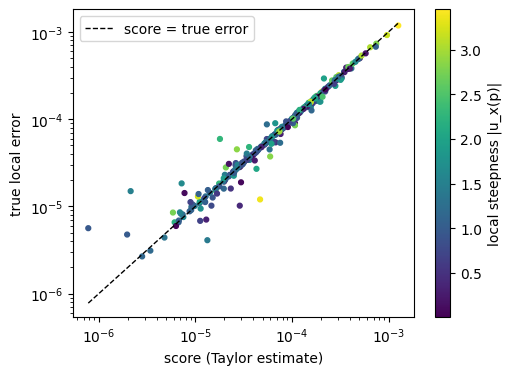

In [46]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients with every time derivative replaced using Burgers, u_t = alpha u_xx - u u_x
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, for random admissible stencils at random points p anywhere in the domain ──
# here the speed a = u(p) and the derivatives are exact (u_true ONLY for this check); colour = local steepness |u_x|
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]                       # exact value at one grid point
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]               # 3 levels down, |dix| <= 3
S, D, G = [], [], []
while len(S) < 300:
    p = (int(rng.integers(3, nx - 3)), int(rng.integers(3, nt)))          # a random interior point
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)
    w = solve_weights(DX, DT, d[0])
    if w is None:
        continue
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S.append(score(DX, DT, w, d)); D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S, D, G = np.array(S), np.array(D), np.array(G)
print(f"300 admissible stencils, |u_x| from {G.min():.2f} to {G.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=G, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

### Rough guess of u and its derivatives
To build the map backward, every point needs, before any value has been computed:
- its local speed $a=u$ (for the weights), and
- the space derivatives $u,u_x,\dots,u_{xxxx}$ (for the score, cell 4).

We take them from a cheap **coarse solve**: Lax–Wendroff on a grid 5× coarser, from the initial condition to $T$, computed once for all queries. At each coarse time, a sine series is fitted through the coarse values ($u=0$ at both walls), which gives the derivatives exactly for the fit. In time we interpolate linearly onto our grid.
The guess only steers **which stencils and weights are chosen**. The values at $z^*$ are computed from the neighbours' values, so a poor guess gives worse choices, never wrong numbers. Its cost (840 points) is added to the method's cost.

coarse grid: 17 x 37 = 629 points (dx 0.0625, dt 1.39e-02)
all points   : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.011  0.023  0.036  0.034  0.079
10% steepest : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.003  0.005  0.074  0.050  0.650


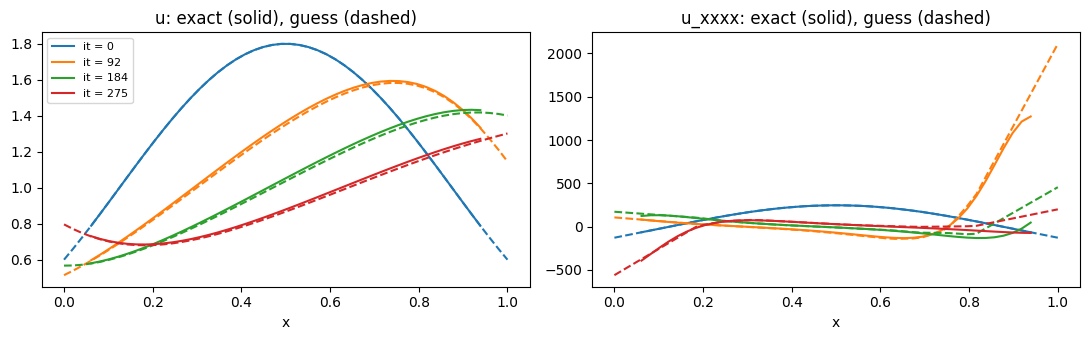

In [47]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score, influence) ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the initial condition to T, with the same boundary data; computed once.
K_COARSE = {"walls": 5, "inflow_smooth": 3, "inflow_front": 2}[PROBLEM]
from scipy.interpolate import make_interp_spline
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
_c2, _c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                 # same stability rule as the main grid
tau = T / int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2))))
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
for j in range(1, len(tc)):
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, a(ui) * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
    Uc.append(n)
G_COARSE = len(xc) * len(tc)                                                  # cost of the guess (grid points)

# ── Smooth fit in x at each coarse time: a quintic spline through the coarse values, differentiated exactly ──
Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    sp = make_interp_spline(xc, u, k=5)
    for k in range(5):
        Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)

# ── Linear in time onto our grid: GUESS[k, it, ix] = k-th x-derivative of the guess at grid point (ix, it) ──
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f  = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                 # (u, u_x, u_xx, u_xxx, u_xxxx) at q

# ── Check: guess vs exact at 300 random points, for all of them and for the 10% steepest (u_true ONLY for this check) ──
print(f"coarse grid: {len(xc)} x {len(tc)} = {G_COARSE} points (dx {hc:.4f}, dt {tau:.2e})")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(3, nx - 3)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex) + 1e-12)
steep = np.abs(ex[:, 1]) >= np.quantile(np.abs(ex[:, 1]), 0.9)
for name, sel in [("all points", slice(None)), ("10% steepest", steep)]:
    print(f"{name:13s}: median relative error for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.3f}" for v in np.median(rel[sel], axis=0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, it in enumerate([0, nt // 3, 2 * nt // 3, nt - 1]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes, [0, 4]):
        ax.plot(x_grid[3:-3], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
for ax in axes: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Backward map and influence β
**The map.** Start at $z^*$ and give it a stencil. Each neighbour that is not known data (IC or wall) becomes a new point that also needs a stencil. Repeat until every branch ends on the IC or a wall. Points are expanded **latest $t$ first**.

**Weights.** No values exist yet while building, so each point $p$ takes its speed from the guess (cell 5), $a_p=u_{\rm guess}(p)$, rounded to steps of 0.02 so the weights can be cached by (shape, speed). Its score uses the guessed derivatives at $p$ (cell 4).

**Influence.** $\beta_p$ = how much an error at $p$ changes the value at $z^*$. Start with $\beta_{z^*}=1$. When $p$ is expanded with weights $w$, pass its influence down: $\beta_q \mathrel{+}= \beta_p\,w_q$.

**Forward pass.** Values are computed bottom-up from the IC and walls, $\hat u_p=\sum_q w_q\hat u_q$, **with the weights chosen in the map**. Recomputing them with another speed would undo the choice: the score was computed for exactly these weights. The guess shapes the stencils and weights, but no guessed value enters $\hat u$.

**Exact identity.** With $\delta_p=u_p-\sum_q w_qu_q$ the local error,
$$e(z^*)=\sum_p\beta_p\,\delta_p .$$
Check: give every point the Lax–Wendroff stencil; the identity must hold to all digits.

In [48]:
# ── Known data: the initial condition and the walls are given, not computed ──
# their values are the exact solution there: u0 at t = 0, the boundary data g_left / g_right on the walls
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed). Solved with the neighbours sorted (latest level first, then left to right), so the
    result never depends on the order the neighbours were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]                  # back to the order of nbs
    return w

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))
# ── Same-level neighbours (upwind only) ──
#   SAME_LEVEL = k > 0 adds the cells (-1, 0) .. (-k, 0): neighbours on p's OWN time level, to its left (upwind for u > 0).
#   To stay explicit (no linear solve): within a level, values are computed LEFT to right (left neighbours are ready),
#   and points are expanded RIGHT to left (every user of a point has passed its influence down before the point is
#   expanded, so beta stays exact). SAME_LEVEL = 0 restores the original window and order (needed for the old agents).
SAME_LEVEL = 0
ORDER = -1 if SAME_LEVEL else 1                      # sign of ix in the pending heap: -1 = right to left within a level

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded LATEST t first (and, within a level, in the order above): every point that can
# use p is expanded before p, so p's influence beta_p is complete when p is expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], ORDER * z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def pending_points(m):
    """The pending points as (ix, it)."""
    return [(ORDER * k, -it) for it, k in m["pending"]]
# ── Same-level neighbours on BOTH sides ──
#   SAME_LEVEL = k > 0 adds the cells (-k..-1, 0) and (1..k, 0): neighbours on p's own time level, left AND right.
#   No linear solve: within a level the same-level links must form no cycle (a mask forbids any link that would close one),
#   so the level can be computed in dependency order. Because a point's same-level users can come after it, its influence
#   beta is only final when its whole level is done: beta is passed down ONE LEVEL AT A TIME, when the level is complete.
#   SAME_LEVEL = 0 gives back the original window (needed for the old agents).

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded latest t first, left to right within a level. Stencils are chosen point by
# point; when the last point of a level is expanded, the level is "closed": its beta is passed down (users before the
# points they use), which completes the beta of the lower points before they are expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {},
            "same": {}, "level": []}               # same: p -> same-level points p uses | level: expanded points of the open level

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def reaches(m, a, b):
    """True if same-level point a uses b, directly or through other same-level points."""
    stack, seen = [a], set()
    while stack:
        q = stack.pop()
        if q == b:
            return True
        if q not in seen:
            seen.add(q); stack.extend(m["same"].get(q, []))
    return False

def forbidden(m, p):
    """Window cells p may not use: same-level points that already use p (directly or not), which would close a cycle."""
    return [k for k in range(N_CELLS) if WINDOW[k][1] == 0 and not is_known(place(p, k)) and reaches(m, place(p, k), p)]

def users_first(m, pts):
    """The points of one level ordered so that every point comes before the same-level points it uses."""
    pts, order, done = set(pts), [], set()
    def visit(q):                                  # depth-first: a point is placed after all its same-level users
        if q in done:
            return
        done.add(q)
        for r in pts:
            if q in m["same"].get(r, []):
                visit(r)
        order.append(q)
    for q in sorted(pts):
        visit(q)
    return order

def close_level(m):
    """Pass the open level's beta down (users first) and return the level's points (their beta is now final)."""
    pts = m["level"]
    for p in users_first(m, pts):
        nbs, w = m["stencil"][p]
        for q, wq in zip(nbs, w):
            if not is_known(q):
                m["beta"][q] += m["beta"][p] * wq
    m["level"] = []
    return pts

def expand(m, nbs):
    """Give the next point the stencil nbs. Returns (p, w, closed): closed = the points whose beta became final now."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    m["same"][p] = [q for q in nbs if q[1] == p[1] and not is_known(q)]
    for q in nbs:
        if not is_known(q) and q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
    m["level"].append(p)
    level_done = not m["pending"] or m["pending"][0][0] != it
    return p, w, (close_level(m) if level_done else [])

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p (it must respect forbidden(m, p))."""
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

# ── Forward pass: values bottom-up; within a level, every point after the same-level points it uses ──
# The map fixes the neighbours (chosen with the guessed speed). Each point then re-solves its weights with the speed
# of its own computed value (picard steps; 0 = keep the map's weights), so the guessed speed never enters the values.
# The weights actually used are kept in m["w_used"] (report needs them).
def forward_order(m):
    order = []
    for t in sorted({p[1] for p in m["stencil"]}):
        order += users_first(m, [p for p in m["stencil"] if p[1] == t])[::-1]
    return order

def evaluate(m, picard=1):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in forward_order(m):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, a(w @ v))             # speed from the value just computed
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat
# ── Check: every point takes the Lax-Wendroff stencil (3 points one level down) ──
# z* = (20, 40) is close enough to the left wall that its cone reaches it: the wall data is used.
# The identity only holds if the known data (IC and walls) is exact.
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]
z = (10, 40)
m = build_map(z, lw)
err = Ug(z) - evaluate(m, picard=0)[z]                       # the map's own weights: the identity must hold exactly
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
n_wall = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[0] in (0, nx - 1) and q[1] > 0)
print(f"LW map at z* = {z}: {len(m['stencil'])} points, {n_wall} uses of wall data | error at z* {abs(err):.2e}")
print(f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")
print(f"with live speed (1 Picard step): error at z* {abs(Ug(z) - evaluate(m)[z]):.2e}")

LW map at z* = (10, 40): 1134 points, 31 uses of wall data | error at z* 6.66e-04
identity: e(z*) = -6.657830e-04, sum beta*delta = -6.657830e-04
with live speed (1 Picard step): error at z* 2.95e-04


### Window, admissible stencils and the mask
**Window.** The candidate neighbours of $p$ are the 21 cells up to 3 to each side and 1 to 3 levels below $p$. A cell past a wall or below $t=0$ is moved onto the wall or the IC (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the admissibility test (cell 3), with $p$'s guessed speed. Points with the same local situation (distance to walls/IC) and the same guessed speed share one list, computed once and cached together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$. The score at a point is then just these moments times the Taylor coefficients at that point (cell 4): one small product per point.
**Mask.** The agent will pick the 5 cells one at a time. A cell may be picked next only if some admissible stencil contains it together with the picks so far, so the agent can never end up with a bad stencil.
**First rule without RL:** every point takes its lowest-score stencil. **Report** gives a finished map's points, its true error at $z^*$ and its exact bound $\sum_p|\beta_p\delta_p|$ (exact solution used only for reporting).

21 window cells | interior point (25, 40): 18768 admissible stencils of 20349
first pick allowed on 21 cells
LW          : 1344 points, error 5.31e-04, exact bound 5.53e-04  (0 s)
lowest score: 1536 points, error 3.62e-05, exact bound 4.72e-04  (13 s)


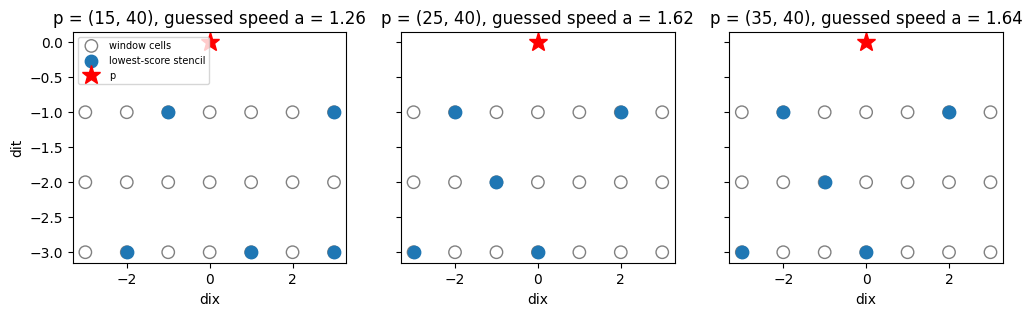

In [49]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = ([(k, 0) for k in list(range(-SAME_LEVEL, 0)) + list(range(1, SAME_LEVEL + 1))]
           + [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)])
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def allowed_sets(m, p):
    """Admissible stencils at p that use no forbidden (cycle-closing) cell: (sets, uses, scores) restricted to them.
    Cached on the map for the current point (it only changes when a stencil is placed), so the 5 picks of a point share it."""
    key = (p, len(m["stencil"]))
    if m.get("_allowed_key") != key:
        sets, uses, sc = admissible(p)
        bad = forbidden(m, p)
        ok = ~uses[:, bad].any(axis=1) if bad else np.ones(len(sets), dtype=bool)
        m["_allowed"] = ([s for s, o in zip(sets, ok) if o], uses[ok], sc[ok]) if bad else (sets, uses, sc)
        m["_allowed_key"] = key
    return m["_allowed"]

def pick_mask(m, p, picks):
    """Cell k may be picked next if some allowed stencil contains the picks so far plus k."""
    _, uses, _ = allowed_sets(m, p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = allowed_sets(m, p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# with the weights the forward pass actually used (live speed); beta is recomputed with them, so e(z*) = sum beta delta
def report(m):
    """Points, true error at z*, exact bound sum |beta delta| with the weights the forward pass used (u_true ONLY here)."""
    z = m["z_star"]
    u_hat, W = evaluate(m), m["w_used"]
    beta = {z: 1.0}
    for p in forward_order(m)[::-1]:                              # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}
z = (25, 40)
sets, _, sc = admissible(z)
print(f"{N_CELLS} window cells | interior point {z}: {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))}")
print("first pick allowed on", pick_mask(start_map(z), z, []).sum(), "cells")
for name, rule in [("LW", lw), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(15, 40), (25, 40), (35, 40)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

In [50]:
def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

In [51]:
# ── Check: same-level neighbours keep the map explicit and the identity exact; what they buy the rules ──
z = (25, 75)
m = build_map(z, lowest_score)
n_same = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1])
err = Ug(z) - evaluate(m, picard=0)[z]                           # the map's own weights: the identity must hold exactly
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
print(f"SAME_LEVEL = {SAME_LEVEL}: {N_CELLS} window cells, {len(admissible(z)[0])} admissible stencils at {z}")
print(f"lowest-score map: {len(m['stencil'])} points, {n_same} uses of same-level neighbours")
print(f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")
for name, rule in [("LW", lw), ("lowest score", lowest_score), ("greedy", greedy_rule(1.0))]:
    mm = build_map(z, rule); rep = report(mm)
    same = sum(1 for p, (nbs, w) in mm["stencil"].items() for q in nbs if q[1] == p[1])
    print(f"{name:>13s}: {rep['points']:5d} points | true error {rep['error']:.1e} | bound {rep['bound']:.1e} | same-level uses {same}")

SAME_LEVEL = 0: 21 window cells, 18743 admissible stencils at (25, 75)
lowest-score map: 3178 points, 0 uses of same-level neighbours
identity: e(z*) = -2.265744e-03, sum beta*delta = -2.265744e-03
           LW:  3024 points | true error 7.9e-04 | bound 8.1e-04 | same-level uses 0
 lowest score:  3178 points | true error 5.3e-05 | bound 1.2e-03 | same-level uses 0
       greedy:  1349 points | true error 4.9e-05 | bound 1.1e-03 | same-level uses 0


### Environment
**Episode.** Build one map for the query $z^*$. At each step the agent picks one window cell for the current point (the latest-$t$ pending point). After 5 picks the stencil is complete, the point is expanded (cell 6), and the next point comes up. The episode ends when no points are pending.
**Mask.** Only cells that can still complete an admissible stencil are allowed (cell 7). Points with a single admissible stencil (next to the IC) are played automatically.
**Reward**, given each time a stencil is complete:
$$r_p=-\frac{|\beta_p|\,s_p}{B_{\rm LW}}-\lambda\,\frac{\text{new points}}{N_{\rm LW}},$$
where $s_p$ is the score (cell 4, with the guessed derivatives), and $B_{\rm LW}$, $N_{\rm LW}$ are the score sum and point count of the Lax–Wendroff map of the same $z^*$. So the total return is $-B/B_{\rm LW}-\lambda(N-1)/N_{\rm LW}$, and LW itself scores $\approx -1-\lambda$.
**Cap.** If the map grows past $3N_{\rm LW}$ points, the episode stops, and each point left unexpanded costs its worst stencil.
**State**, for the current point $p$:
- per window cell: already picked, already in the map (reusing it is free), known data (IC/wall), and the best score still reachable through it;
- and globally: $\log|\beta_p|$, levels above the IC, offset to $z^*$, pick number, points used so far, and the pending workload (points still waiting and their total influence).

In [52]:
# ── Units of the reward ──
#   accuracy: the estimated error share |beta_p| s_p, in units of EPS (a fixed target error for the problem, same for every query)
#   cost:     new points, in units of N_LW (the point count of the Lax-Wendroff map of the same z*: "a classical solve")
EPS = {"walls": 1e-5, "inflow_smooth": 1e-3, "inflow_front": 1e-4}[PROBLEM]
_nlw_cache = {}
def n_lw(z):
    """Points of the LW map of z* (the cost unit)."""
    if z not in _nlw_cache:
        _nlw_cache[z] = len(build_map(z, lw)["stencil"])
    return _nlw_cache[z]

# ── State switch: per-cell physics features ──
#   STATE_X = True adds, for every window cell q, two numbers to the state:
#     xi_q / dx : the cell's offset from the foot of the characteristic (with p's guessed speed): which side is upwind, how far
#     R_q       : the cell's Taylor remainder, the part of the local Taylor polynomial the three conditions do NOT cancel,
#                 so the score of ANY stencil at p is |sum_q w_q R_q|  (signed log of R_q / dx^3, which spans ~1 .. 1000)
STATE_X = True
def cell_features(p):
    d, ap = guess_derivs(p), a_build(p)
    off = np.array([(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)], dtype=float)
    DX, DT = off[:, 0] * dx, off[:, 1] * dt
    xi = DX - ap * DT
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    R = P - d[1] * xi - d[2] * (0.5 * xi**2 + alpha * DT)
    return np.concatenate([xi / dx, np.sign(R) * np.log10(1 + np.abs(R) / dx**3)])


# ── Environment: one step = one pick; a reward each time a stencil is complete ──
#   reward of a stencil at p:  -|beta_p| s_p / EPS  -  lam * (new points) / N_LW
#   lam (the price of a point) is drawn per episode, log-uniform in lam_range, and shown to the agent
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
N_OBS   = 3 * N_CELLS + 12 + (2 * N_CELLS if STATE_X else 0)

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(0.1, 10.0), cap=3.0):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS)               # one action = one window cell

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self._play_forced()
        return self._obs(), {}

    def _complete(self, cells):
        """Expand the next point with these cells. Reward: the points' cost now; the accuracy terms of a level when it closes."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, _, closed = expand(self.m, nbs)
        return -self._accuracy(closed) - self.lam * n_new / self.N_ref

    def _accuracy(self, pts):
        """Sum of |beta_p| s_p / EPS over points whose beta is final."""
        term = sum(abs(self.m["beta"][q]) * point_score(q, *self.m["stencil"][q]) for q in pts)
        self.B += term
        return term / EPS

    def _play_forced(self):
        """Points with only one allowed stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            sets, _, _ = allowed_sets(self.m, next_point(self.m))
            if len(sets) != 1:
                break
            r += self._complete(sets[0])
        return r

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = [(ix, -it) for it, ix in self.m["pending"]]
        d      = guess_derivs(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam)]                                # price of a point
        feats = [cell_features(p)] if STATE_X else []
        return np.concatenate([picked, exists, known, glob] + feats).astype(np.float32)
    def step(self, k):
        self.picks.append(int(k))
        p = next_point(self.m)
        if len(self.picks) < len(allowed_sets(self.m, p)[0][0]):   # still choosing p's stencil (fewer cells near the walls)
            return self._obs(), 0.0, False, False, {}
        r = self._complete(self.picks)
        self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: close the open level, then each point left unexpanded costs its worst stencil
        r -= self._accuracy(close_level(self.m)) if self.m["level"] else 0.0
        for it, ix in self.m["pending"]:
            q = (ix, -it)
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / EPS
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "lam": self.lam,
                "score_ratio": self.B / EPS, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        return pick_mask(self.m, next_point(self.m), self.picks)

# ── Check: one episode with random (masked) picks; the rewards must add up to the return formula ──
env = MapEnv(queries=[(25, 40)])
obs, _ = env.reset(seed=0)
rng, total, steps, done = np.random.default_rng(0), 0.0, 0, False
while not done:
    obs, r, done, _, info = env.step(rng.choice(np.flatnonzero(env.action_masks())))
    total += r; steps += 1
print(f"obs size {N_OBS} | lam = {info['lam']:.2f} | {steps} picks | finished: {info['finished']} | "
      f"{info['points']} points ({info['points_ratio']:.2f}x LW) | score sum {info['score_ratio']:.1f} EPS")
print(f"sum of rewards {total:.3f}   check: -B/EPS - lam*(points-1)/N_LW = "
      f"{-info['score_ratio'] - info['lam'] * (info['points'] - 1) / env.N_ref:.3f}")

obs size 117 | lam = 1.88 | 7745 picks | finished: True | 1551 points (1.15x LW) | score sum 3.5 EPS
sum of rewards -5.672   check: -B/EPS - lam*(points-1)/N_LW = -5.672


### Map figure
One figure for any finished map, used for the baselines and the training videos:
1. the map, coloured by influence $|\beta_p|$ on $z^*$;
2. a zoom on $z^*$ with the stencils of the top levels;
3. the accumulated error $|\hat u_p-u_p|$ at every computed point;
4. the error share $|\beta_p\delta_p|$ of every point (these add up to the exact bound).

Panels 3 and 4 use the exact solution, only for this figure.

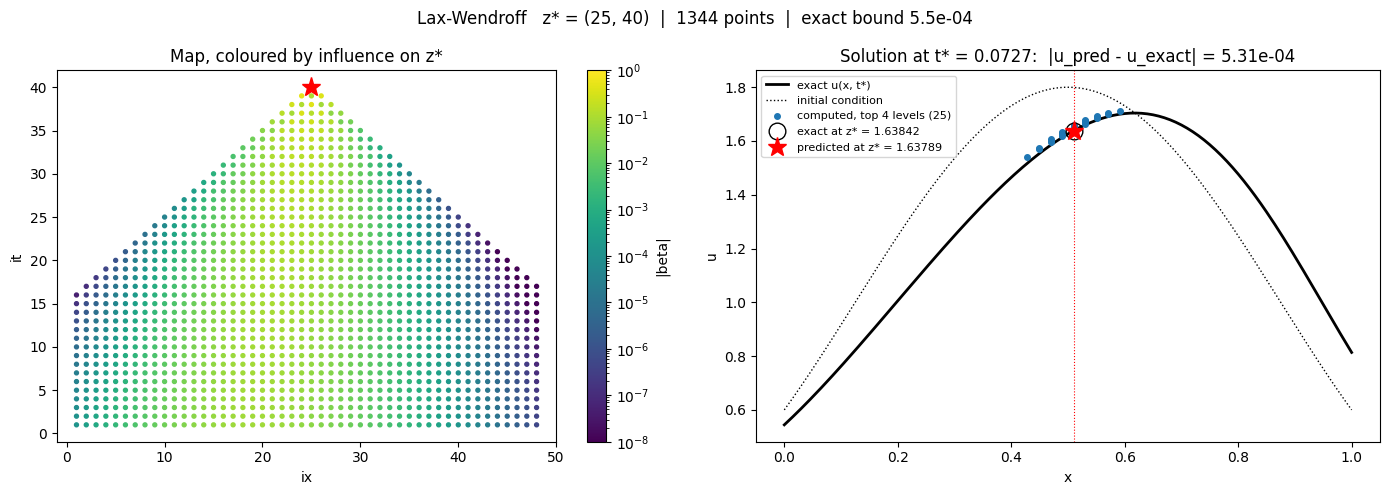

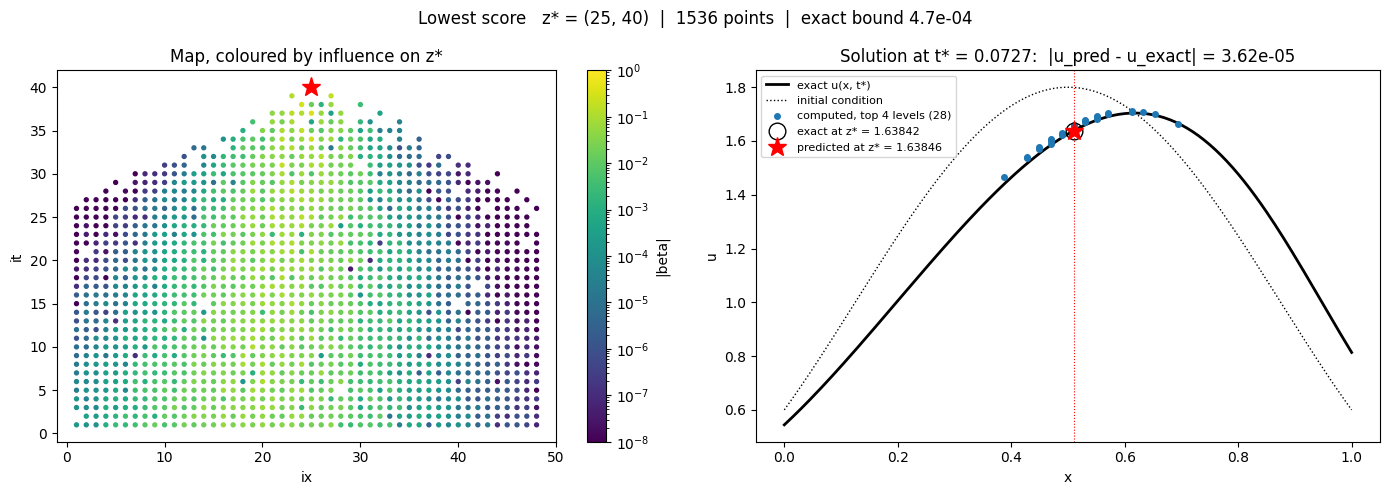

In [53]:
# ── One figure for any finished map (used for the baselines and the training videos) ──
#   left : the map, coloured by influence |beta| on z*
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("Map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4,
            label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"Solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

plot_map(build_map((25 , 40), lw), "Lax-Wendroff")
plot_map(build_map((25, 40), lowest_score), "Lowest score")

### Training helpers and callbacks
- `make_env`: one training environment (with the action mask and the episode monitor).
- `run_policy`: one episode where the policy takes its most likely pick every time; returns the finished map.
- `MapLogCallback`: logs points, score sum (both relative to LW) and the finish rate of the training episodes to TensorBoard.
- `SnapshotCallback`: every `every` steps, runs the current policy on one query, saves its map figure (cell 9) and keeps its numbers. These images become the training-progress video.

All take an environment class (`env_cls`), so the same helpers serve the multi-query environment later.
Check: a tiny run (2 environments, 2048 steps) to see that everything connects.

In [54]:
# ── Helpers for training: environment factory and one deterministic run of a trained policy ──
def make_env(queries, lam_range, seed, env_cls=MapEnv):
    def _init():
        env = Monitor(ActionMasker(env_cls(queries=queries, lam_range=lam_range), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* at a fixed lam, with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam_range=(lam, lam))
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: log map numbers of every finished training episode (mean of the last 100) ──
class MapLogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.hist = {"points_ratio": [], "score_ratio": [], "finished": []}

    def _on_step(self):
        for info in self.locals["infos"]:
            if "points_ratio" in info:                              # only at the end of an episode
                for k in self.hist:
                    self.hist[k].append(float(info[k]))
        for k, v in self.hist.items():
            if v:
                self.logger.record(f"map/{k}", np.mean(v[-100:]))
        return True

# ── Callback 2: every `every` steps, run the current policy on z_plot at a fixed lam, save the figure and the numbers ──
class SnapshotCallback(BaseCallback):
    def __init__(self, z_plot, lam, every, img_dir, env_cls=MapEnv):
        super().__init__()
        self.z_plot, self.lam, self.every, self.img_dir, self.env_cls = z_plot, lam, every, img_dir, env_cls
        self.last, self.hist, self.episodes = -every, [], 0

    def _on_step(self):
        self.episodes += sum("episode" in info for info in self.locals["infos"])   # maps finished in training
        if self.num_timesteps - self.last >= self.every:
            self.last = self.num_timesteps
            env = run_policy(self.model, self.z_plot, self.lam, self.env_cls)
            if env.info["finished"]:
                rep = report(env.m)
                plot_map(env.m, f"step {self.num_timesteps:,}  ({self.episodes} maps)  |  lam {self.lam:g}  |  return {env.ret:.2f}",
                         os.path.join(self.img_dir, f"map_{self.num_timesteps:09d}.png"))
            else:
                rep = {"points": env.info["points"], "error": np.nan, "bound": np.nan}
            self.hist.append({"step": self.num_timesteps, "episodes": self.episodes, "return": env.ret, **rep})
            print(f"step {self.num_timesteps:>10,} | {self.episodes:5d} maps: return {env.ret:7.2f} | "
                  f"{rep['points']} points | bound {rep['bound']:.1e} | finished {env.info['finished']}")
        return True

In [55]:
# ── Self-contained: the rules this cell needs (overrides any earlier, broken copies) ──
def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

assert callable(greedy_rule(1.0)), "greedy_rule is broken"
def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

In [56]:
# ── Check: both-sided same-level neighbours: no cycles, exact identity, and what the rules do with them ──
def same_level_use(m):
    """How often stencils use same-level neighbours on the left (upwind for u > 0) and on the right (downwind)."""
    left = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1] and q[0] < p[0] and not is_known(q))
    right = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1] and q[0] > p[0] and not is_known(q))
    return left, right

z = (25, 75)
print(f"SAME_LEVEL = {SAME_LEVEL}: {N_CELLS} window cells, {len(admissible(z)[0])} admissible stencils at {z}")
rng = np.random.default_rng(0)
def random_rule(m, p):                                            # random allowed stencils: the hardest test for cycles
    sets, _, _ = allowed_sets(m, p)
    return [place(p, k) for k in sets[rng.integers(len(sets))]]
for name, rule in [("random", random_rule), ("lowest score", lowest_score)]:
    m = build_map(z, rule)
    order = forward_order(m)
    assert len(order) == len(m["stencil"]), "a point is missing from the dependency order (cycle?)"
    err = Ug(z) - evaluate(m, picard=0)[z]                        # the map's own weights: the identity must hold exactly
    delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
    print(f"{name:>13s}: {len(m['stencil'])} points | same-level left / right {same_level_use(m)} | "
          f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")
for name, rule in [("LW", lw), ("lowest score", lowest_score), ("greedy", greedy_rule(1.0))]:
    mm = build_map(z, rule); rep = report(mm)
    print(f"{name:>13s}: {rep['points']:5d} points | true error {rep['error']:.1e} | bound {rep['bound']:.1e} | "
          f"same-level left / right {same_level_use(mm)}")

SAME_LEVEL = 0: 21 window cells, 18743 admissible stencils at (25, 75)
       random: 3173 points | same-level left / right (0, 0) | identity: e(z*) = -1.746584e-03, sum beta*delta = -1.746584e-03
 lowest score: 3178 points | same-level left / right (0, 0) | identity: e(z*) = -2.265744e-03, sum beta*delta = -2.265744e-03
           LW:  3024 points | true error 7.9e-04 | bound 8.1e-04 | same-level left / right (0, 0)
 lowest score:  3178 points | true error 5.3e-05 | bound 1.2e-03 | same-level left / right (0, 0)
       greedy:  1349 points | true error 4.9e-05 | bound 1.1e-03 | same-level left / right (0, 0)


### Training
MaskablePPO, $\gamma=1$, `gae_lambda` and `ent_coef` as set in `PPO_KW`. One query (`Z_TRAIN`), λ from `LAM_RANGE`.
Everything a run produces goes into `runs{month}-{day}/{run_name}/`: `config.json` (all settings), `images/` (snapshot figures + final map),
`checkpoints/` (models), `logs/` (TensorBoard), `snapshots.json` (return, points, error, bound at every snapshot).
The stencil cache is not copied to the workers; each fills its own.

In [ ]:
print(f"EPS = {EPS:.0e}")      # should be 1e-03


EPS = 1e-03
0 21 117 True


In [60]:
# ══ Screening run (5M steps): same-level neighbours on both sides, IC peak at the middle, one seed ══
#   Compare with the old-window agent at the same number of steps (its 5M checkpoint), not with a 20M model.
#   8 workers: with both-sided cells each worker's stencil table takes ~1.5 GB of memory.
import json
from stable_baselines3.common.callbacks import CheckpointCallback

Z_TRAIN   = (25, 75)
QUERIES   = [Z_TRAIN]
LAM_RANGE = (1.0, 1.0)
LAM_PLOT  = 1.0
SEED      = 1
TOTAL     = 5_000_000
N_ENVS    = 8
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW = dict(n_steps=4096, batch_size=4096, n_epochs=5, gamma=1.0, gae_lambda=0.97,
              learning_rate=1e-4, clip_range=0.1, target_kl=0.02, ent_coef=0.0)
run_name = f"{PROBLEM}_peak{X_PK:g}_same{SAME_LEVEL}_state{'X' if STATE_X else '0'}_stable_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM_RANGE[0]:g}-{LAM_RANGE[1]:g}_seed{SEED}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, ic=dict(C_BG=C_BG, A_W=A_W, L_W=L_W, X_PK=X_PK), same_level=SAME_LEVEL, alpha=alpha, T=T,
                   nx=nx, nt=nt, queries=QUERIES, lam_range=LAM_RANGE, eps=EPS, seed=SEED, total=TOTAL, n_envs=N_ENVS,
                   ppo=PPO_KW, K_COARSE=K_COARSE, N_OBS=N_OBS, window=dict(R_X=R_X, K_T=K_T, N_NB=N_NB, cells=WINDOW),
                   date=str(date.today())), f, indent=2)
print("run folder:", run_dir)

for z in QUERIES:
    n_lw(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, LAM_RANGE, seed=100 * SEED + i) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=SEED, verbose=0, device="cpu",
                    tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)
snap_cb = SnapshotCallback(Z_TRAIN, LAM_PLOT, every=SNAP_EVERY, img_dir=img_dir)
t0 = time.time()
try:
    model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
                callback=[MapLogCallback(), snap_cb,
                          CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
finally:
    vec.close()
    with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
        json.dump(snap_cb.hist, f, indent=1, default=float)
model.save(os.path.join(ckpt_dir, "ppo_final"))
print(f"training time: {(time.time() - t0) / 60:.0f} min")

# ── the trained agent, the rules, and how often each uses upwind (left) vs downwind (right) same-level neighbours ──
m = run_policy(model, Z_TRAIN, LAM_PLOT).m
plot_map(m, f"final  |  same-level {SAME_LEVEL}  |  lam {LAM_PLOT:g}", os.path.join(img_dir, "map_final.png"))
print(f"\nat {Z_TRAIN}, lam = {LAM_PLOT:g}:")
for name, mm in [("agent", m), ("LW", build_map(Z_TRAIN, lw)), ("lowest score", build_map(Z_TRAIN, lowest_score)),
                 ("greedy", build_map(Z_TRAIN, greedy_rule(LAM_PLOT)))]:
    rep = report(mm)
    print(f"{name:>13s}: return {-score_sum(mm) / EPS - LAM_PLOT * (rep['points'] - 1) / n_lw(Z_TRAIN):6.2f} | {rep['points']:5d} points | "
          f"bound {rep['bound']:.1e} | error {rep['error']:.1e} | same-level left / right {same_level_use(mm)}")

run folder: runs10-21\inflow_smooth_peak0.5_same0_stateX_stable_z25-75_lam1-1_seed1
step          8 |     0 maps: return   -6.80 | 3217 points | bound 4.7e-03 | finished True
step    250,008 |     8 maps: return   -4.94 | 3139 points | bound 3.8e-03 | finished True
step    500,008 |    24 maps: return  -15.41 | 3271 points | bound 1.3e-02 | finished True
step    750,008 |    40 maps: return   -9.48 | 3248 points | bound 7.3e-03 | finished True
step  1,000,008 |    56 maps: return   -4.36 | 3200 points | bound 2.7e-03 | finished True
step  1,250,008 |    72 maps: return   -3.72 | 3253 points | bound 2.5e-03 | finished True
step  1,500,008 |    88 maps: return   -8.62 | 3291 points | bound 6.6e-03 | finished True
step  1,750,008 |   104 maps: return   -5.48 | 3293 points | bound 3.8e-03 | finished True
step  2,000,008 |   120 maps: return   -9.02 | 3294 points | bound 7.1e-03 | finished True
step  2,250,008 |   136 maps: return  -10.62 | 3293 points | bound 8.9e-03 | finished True
step  

In [42]:
def same_level_use(m):
    """How often stencils use same-level neighbours on the left (upwind for u > 0) and on the right (downwind)."""
    left = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1] and q[0] < p[0] and not is_known(q))
    right = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1] and q[0] > p[0] and not is_known(q))
    return left, right

m = run_policy(model, Z_TRAIN, LAM_PLOT).m
plot_map(m, f"final  |  same-level {SAME_LEVEL}  |  lam {LAM_PLOT:g}", os.path.join(img_dir, "map_final.png"))
print(f"\nat {Z_TRAIN}, lam = {LAM_PLOT:g}:")
for name, mm in [("agent", m), ("LW", build_map(Z_TRAIN, lw)), ("lowest score", build_map(Z_TRAIN, lowest_score)),
                 ("greedy", build_map(Z_TRAIN, greedy_rule(LAM_PLOT)))]:
    rep = report(mm)
    print(f"{name:>13s}: return {-score_sum(mm) / EPS - LAM_PLOT * (rep['points'] - 1) / n_lw(Z_TRAIN):6.2f} | {rep['points']:5d} points | "
          f"bound {rep['bound']:.1e} | error {rep['error']:.1e} | same-level left / right {same_level_use(mm)}")


for name, mm in [("agent", m), ("LW", build_map(Z_TRAIN, lw)), ("lowest score", build_map(Z_TRAIN, lowest_score)),
                 ("greedy", build_map(Z_TRAIN, greedy_rule(LAM_PLOT)))]:
    rep = report(mm)
    print(f"{name:>13s}: return {-score_sum(mm) / EPS - LAM_PLOT * (rep['points'] - 1) / n_lw(Z_TRAIN):6.2f} | {rep['points']:5d} points | "
          f"bound {rep['bound']:.1e} | error {rep['error']:.1e} | same-level left / right {same_level_use(mm)}")


at (25, 75), lam = 1:
        agent: return  -2.45 |  3258 points | bound 2.8e-04 | error 1.4e-04 | same-level left / right (0, 0)
           LW: return  -2.45 |  3024 points | bound 8.1e-04 | error 7.9e-04 | same-level left / right (0, 0)
 lowest score: return  -1.05 |  3178 points | bound 1.2e-03 | error 5.3e-05 | same-level left / right (0, 0)
       greedy: return  -0.53 |  1349 points | bound 1.1e-03 | error 4.9e-05 | same-level left / right (0, 0)
        agent: return  -2.45 |  3258 points | bound 2.8e-04 | error 1.4e-04 | same-level left / right (0, 0)
           LW: return  -2.45 |  3024 points | bound 8.1e-04 | error 7.9e-04 | same-level left / right (0, 0)
 lowest score: return  -1.05 |  3178 points | bound 1.2e-03 | error 5.3e-05 | same-level left / right (0, 0)
       greedy: return  -0.53 |  1349 points | bound 1.1e-03 | error 4.9e-05 | same-level left / right (0, 0)


In [62]:
# ══ Imitation start: copy greedy's picks (DAgger), then check the clone BEFORE any PPO ══
#   greedy is only the teacher here: the trained policy never calls it.
#   DAgger: round 1 rolls out greedy itself; later rounds let the clone build the maps (greedy follows with prob p_expert),
#   and greedy labels every state the clone reaches with the cell it would pick there.
#   The value net is fitted to the returns-to-go of the same rollouts, so PPO does not start with a random critic.
import json, torch
from stable_baselines3.common.callbacks import CheckpointCallback

Z_TRAIN, LAM = (25, 50), 1.0
QUERIES   = [Z_TRAIN]
DAGGER    = [(1.0, 3), (0.5, 3), (0.25, 3), (0.0, 3)]   # (probability of following greedy, episodes) per round
N_ENVS    = 12
PPO_KW    = dict(n_steps=1024, batch_size=1024, n_epochs=5, gamma=1.0, gae_lambda=0.95,
                 learning_rate=1e-4, clip_range=0.1, ent_coef=0.0)

def greedy_pick(env):
    """Greedy's next cell in any state: the best stencil that still contains the picks so far, its first unpicked cell."""
    p = next_point(env.m)
    sets, uses, sc = admissible(p)
    ok = uses[:, env.picks].all(axis=1) if env.picks else np.ones(len(sets), dtype=bool)
    new = np.array([not is_known(place(p, k)) and place(p, k) not in env.m["beta"] for k in range(N_CELLS)])
    cost = abs(env.m["beta"][p]) * sc / EPS + env.lam * (uses.astype(float) @ new) / env.N_ref
    cost[~ok] = np.inf
    return min(k for k in sets[int(np.argmin(cost))] if k not in env.picks)

def collect(model, p_expert, n_episodes, rng):
    """Roll out (greedy with probability p_expert, else the model); label every state with greedy's pick."""
    O, Y, M, R = [], [], [], []
    for _ in range(n_episodes):
        env = MapEnv(QUERIES, (LAM, LAM)); obs, _ = env.reset(seed=int(rng.integers(1_000_000)))
        rews, done = [], False
        while not done:
            mask, y = env.action_masks(), greedy_pick(env)
            O.append(obs); Y.append(y); M.append(mask)
            act = y if rng.random() < p_expert else int(model.predict(obs, action_masks=mask, deterministic=False)[0])
            obs, r, done, _, _ = env.step(act); rews.append(r)
        R.extend(np.cumsum(rews[::-1])[::-1])                    # return-to-go from each state
    return O, Y, M, R

def bc_train(model, O, Y, M, R, epochs=30, batch=512, lr=1e-3):
    """Supervised: maximise log-prob of greedy's picks (masked), and fit the value net to the returns-to-go."""
    O, Y, M, R = np.array(O, np.float32), np.array(Y), np.array(M), np.array(R, np.float32)
    opt, r_var = torch.optim.Adam(model.policy.parameters(), lr=lr), R.var() + 1e-8
    for _ in range(epochs):
        for b in np.array_split(np.random.permutation(len(O)), max(len(O) // batch, 1)):
            values, logp, _ = model.policy.evaluate_actions(torch.as_tensor(O[b]), torch.as_tensor(Y[b]), action_masks=M[b])
            loss = -logp.mean() + 0.5 * ((values.flatten() - torch.as_tensor(R[b]))**2).mean() / r_var
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        _, logp, _ = model.policy.evaluate_actions(torch.as_tensor(O), torch.as_tensor(Y), action_masks=M)
    return float(np.exp(logp.numpy()).mean())                  # mean probability given to greedy's pick

def describe(m):
    """Return (at LAM), points, bound, true error, and how deep the stencils reach (share whose deepest cell is 1/2/3 levels down)."""
    rep = report(m)
    deepest = np.array([max(p[1] - q[1] for q in nbs) for p, (nbs, w) in m["stencil"].items()])
    ret = -score_sum(m) / EPS - LAM * (rep["points"] - 1) / n_lw(Z_TRAIN)
    return (f"return {ret:6.2f} | {rep['points']:5d} points | bound {rep['bound']:.1e} | error {rep['error']:.1e} | "
            f"depth 1/2/3: " + " / ".join(f"{np.mean(deepest == k):.0%}" for k in (1, 2, 3)))

# ── Run folder ──
run_name = f"{PROBLEM}_imitation_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM:g}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, nx=nx, queries=QUERIES, lam=LAM, eps=EPS, K_COARSE=K_COARSE, N_OBS=N_OBS,
                   dagger=DAGGER, ppo=PPO_KW, date=str(date.today())), f, indent=2)
print("run folder:", run_dir)
print(f"{'LW':>8s}: {describe(build_map(Z_TRAIN, lw))}")
print(f"{'greedy':>8s}: {describe(build_map(Z_TRAIN, greedy_rule(LAM)))}\n")

# ── Model (workers start now; the imitation runs in this process) ──
for z in QUERIES:
    n_lw(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, (LAM, LAM), seed=100 + i) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=1, verbose=0, device="cpu", tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)

# ── DAgger ──
rng, data, t0 = np.random.default_rng(0), ([], [], [], []), time.time()
for rnd, (p_expert, n_ep) in enumerate(DAGGER):
    for store, new in zip(data, collect(model, p_expert, n_ep, rng)):
        store.extend(new)
    agree = bc_train(model, *data)
    clone = run_policy(model, Z_TRAIN, LAM).m
    print(f"round {rnd} (greedy prob {p_expert}): {len(data[0])} states, P(greedy's pick) {agree:.2f} | "
          f"clone: {describe(clone)}  ({(time.time() - t0) / 60:.0f} min)")
model.save(os.path.join(ckpt_dir, "clone"))
plot_map(clone, f"clone after imitation  |  lam {LAM:g}", os.path.join(img_dir, "map_clone.png"))

# ── The check: go on to PPO (next cell) only if the clone beats the agent trained from scratch (return -1.48),
#    with clearly fewer points than LW and most stencils reaching 2-3 levels down ──
print("\nfrom-scratch agent for comparison: return -1.48 | 1899 points | depth 1/2/3: 91% / 7% / 2%")

run folder: runs10-15\inflow_smooth_imitation_z25-50_lam1
      LW: return  -1.73 |  1824 points | bound 5.7e-04 | error 3.9e-04 | depth 1/2/3: 100% / 0% / 0%
  greedy: return  -0.53 |   834 points | bound 4.3e-04 | error 5.2e-05 | depth 1/2/3: 5% / 34% / 61%

round 0 (greedy prob 1.0): 12495 states, P(greedy's pick) 0.64 | clone: return  -2.36 |   609 points | bound 1.6e-03 | error 9.4e-05 | depth 1/2/3: 2% / 26% / 72%  (0 min)
round 1 (greedy prob 0.5): 27165 states, P(greedy's pick) 0.61 | clone: return  -2.20 |   586 points | bound 1.6e-03 | error 1.8e-05 | depth 1/2/3: 3% / 19% / 79%  (1 min)
round 2 (greedy prob 0.25): 42560 states, P(greedy's pick) 0.58 | clone: return  -2.17 |   646 points | bound 1.5e-03 | error 2.2e-05 | depth 1/2/3: 2% / 28% / 70%  (1 min)
round 3 (greedy prob 0.0): 57985 states, P(greedy's pick) 0.56 | clone: return  -1.97 |   715 points | bound 1.3e-03 | error 2.4e-04 | depth 1/2/3: 6% / 25% / 68%  (1 min)

from-scratch agent for comparison: return -1.48 |

In [63]:
# ══ PPO fine-tuning from the clone: small learning rate and clip range, to improve on it without wrecking it ══
TOTAL = 5_000_000
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
snap_cb = SnapshotCallback(Z_TRAIN, LAM, every=SNAP_EVERY, img_dir=img_dir)
t0 = time.time()
model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
            callback=[MapLogCallback(), snap_cb,
                      CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
vec.close()
print(f"fine-tuning time: {(time.time() - t0) / 60:.0f} min")
model.save(os.path.join(ckpt_dir, "ppo_final"))
with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
    json.dump(snap_cb.hist, f, indent=1, default=float)
final = run_policy(model, Z_TRAIN, LAM).m
plot_map(final, f"final (imitation + PPO)  |  lam {LAM:g}", os.path.join(img_dir, "map_final.png"))
print(f"final: {describe(final)}")

step         12 |     0 maps: return   -1.97 | 715 points | bound 1.3e-03 | finished True
step    250,020 |    36 maps: return   -1.91 | 1081 points | bound 1.0e-03 | finished True
step    500,028 |    69 maps: return   -1.57 | 1665 points | bound 4.1e-04 | finished True
step    750,036 |    96 maps: return   -1.55 | 1639 points | bound 4.0e-04 | finished True
step  1,000,044 |   130 maps: return   -1.48 | 1632 points | bound 3.4e-04 | finished True
step  1,250,052 |   156 maps: return   -1.45 | 1608 points | bound 3.2e-04 | finished True
step  1,500,060 |   186 maps: return   -1.50 | 1684 points | bound 3.3e-04 | finished True
step  1,750,068 |   216 maps: return   -1.47 | 1718 points | bound 2.8e-04 | finished True
step  2,000,076 |   240 maps: return   -1.47 | 1632 points | bound 3.1e-04 | finished True
step  2,250,084 |   274 maps: return   -1.47 | 1670 points | bound 2.9e-04 | finished True
step  2,500,092 |   300 maps: return   -1.45 | 1662 points | bound 2.9e-04 | finished True


## Keep everything below this, don't run it now


In [ ]:
# ══ Everything-in run: richer state + imitation of greedy (DAgger) + PPO fine-tuning from the clone ══
#   1) state + u_xxx, u_xxxx (the terms that decide which stencils really cancel)
#   2) imitation: copy greedy's picks; DAgger rounds label the clone's own states with greedy's choice
#   3) the value network is trained on the same rollouts (returns-to-go), so PPO does not start with a random critic
#   4) PPO fine-tuning: gae_lambda 0.95, small learning rate and clip range, to improve on the clone without wrecking it
import json, torch
from stable_baselines3.common.callbacks import CheckpointCallback

LAM       = 1.0                 # fixed price of a point (as in the scratch runs)
QUERIES   = [Z_TRAIN]
DAGGER    = [(1.0, 3), (0.5, 3), (0.25, 3), (0.0, 3)]   # (probability of following greedy, episodes) per round
TOTAL     = 3_000_000           # PPO fine-tuning steps
N_ENVS    = 12
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW    = dict(n_steps=1024, batch_size=1024, n_epochs=5, gamma=1.0, gae_lambda=0.95,
                 learning_rate=1e-4, clip_range=0.1, ent_coef=0.0)

# ── 1) richer state ──
N_OBS_X = N_OBS + 2
class MapEnvX(MapEnv):
    def __init__(self, queries, lam_range=(1.0, 1.0), cap=3.0):
        super().__init__(queries, lam_range, cap)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS_X,), dtype=np.float32)
    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS_X, np.float32)
        d = guess_derivs(next_point(self.m))
        return np.concatenate([super()._obs(), [d[3] * L_SCALE**3, d[4] * L_SCALE**4]]).astype(np.float32)
    def step(self, k):
        obs, r, done, trunc, info = super().step(k)
        return (np.zeros(N_OBS_X, np.float32) if done else obs), r, done, trunc, info

# ── 2) greedy's next pick in any state: the best stencil that still contains the picks so far, its first unpicked cell ──
def greedy_pick(env):
    p = next_point(env.m)
    sets, uses, sc = admissible(p)
    ok = uses[:, env.picks].all(axis=1) if env.picks else np.ones(len(sets), dtype=bool)
    new = np.array([not is_known(place(p, k)) and place(p, k) not in env.m["beta"] for k in range(N_CELLS)])
    cost = abs(env.m["beta"][p]) * sc / EPS + env.lam * (uses.astype(float) @ new) / env.N_ref
    cost[~ok] = np.inf
    return min(k for k in sets[int(np.argmin(cost))] if k not in env.picks)

def collect(model, p_expert, n_episodes, rng):
    """Roll out (greedy with probability p_expert, else the model); label every state with greedy's pick."""
    O, Y, M, R = [], [], [], []
    for _ in range(n_episodes):
        env = MapEnvX(QUERIES, (LAM, LAM)); obs, _ = env.reset(seed=int(rng.integers(1_000_000)))
        rews, done = [], False
        while not done:
            mask, y = env.action_masks(), greedy_pick(env)
            O.append(obs); Y.append(y); M.append(mask)
            a = y if rng.random() < p_expert else int(model.predict(obs, action_masks=mask, deterministic=False)[0])
            obs, r, done, _, _ = env.step(a); rews.append(r)
        R.extend(np.cumsum(rews[::-1])[::-1])                    # return-to-go from each state
    return O, Y, M, R

def bc_train(model, O, Y, M, R, epochs=30, batch=512, lr=1e-3):
    """Supervised: maximise log-prob of greedy's picks (masked), and fit the value net to the returns-to-go."""
    O, Y, M, R = np.array(O, np.float32), np.array(Y), np.array(M), np.array(R, np.float32)
    opt, r_var = torch.optim.Adam(model.policy.parameters(), lr=lr), R.var() + 1e-8
    for _ in range(epochs):
        for b in np.array_split(np.random.permutation(len(O)), max(len(O) // batch, 1)):
            values, logp, _ = model.policy.evaluate_actions(torch.as_tensor(O[b]), torch.as_tensor(Y[b]), action_masks=M[b])
            loss = -logp.mean() + 0.5 * ((values.flatten() - torch.as_tensor(R[b]))**2).mean() / r_var
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        _, logp, _ = model.policy.evaluate_actions(torch.as_tensor(O), torch.as_tensor(Y), action_masks=M)
    return float(np.exp(logp.numpy()).mean())                  # mean probability given to greedy's pick

def evaluate_policy(model):
    env = run_policy(model, Z_TRAIN, LAM, MapEnvX)
    rep = report(env.m)
    return env, f"return {env.ret:7.2f} | {rep['points']:5d} points | bound {rep['bound']:.1e} | skew {skew_slope(env.m):.2f}"

# ── Run folder ──
run_name = f"{PROBLEM}_imitation_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM:g}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, queries=QUERIES, lam_range=(LAM, LAM), eps=EPS, K_COARSE=K_COARSE, N_OBS=N_OBS_X,
                   dagger=DAGGER, total=TOTAL, ppo=PPO_KW, date=str(date.today())), f, indent=2)
print("run folder:", run_dir)

# ── The reference: greedy's own map ──
mg = build_map(Z_TRAIN, greedy_rule(LAM)); rg = report(mg)
print(f"greedy   : return {-score_sum(mg) / EPS - LAM * (rg['points'] - 1) / n_lw(Z_TRAIN):7.2f} | {rg['points']:5d} points | "
      f"bound {rg['bound']:.1e} | skew {skew_slope(mg):.2f}")

# ── Model (workers start now; the imitation runs in this process) ──
for z in QUERIES:
    n_lw(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, (LAM, LAM), seed=100 + i, env_cls=MapEnvX) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=1, verbose=0, device="cpu", tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)

# ── 2-3) Imitation with DAgger ──
rng, data, t0 = np.random.default_rng(0), ([], [], [], []), time.time()
for rnd, (p_expert, n_ep) in enumerate(DAGGER):
    for store, new in zip(data, collect(model, p_expert, n_ep, rng)):
        store.extend(new)
    agree = bc_train(model, *data)
    _, line = evaluate_policy(model)
    print(f"DAgger round {rnd} (greedy prob {p_expert}): {len(data[0])} labelled states, P(greedy's pick) {agree:.2f} | "
          f"clone: {line}  ({(time.time() - t0) / 60:.0f} min)")
model.save(os.path.join(ckpt_dir, "clone"))
env, _ = evaluate_policy(model)
plot_map(env.m, f"clone after imitation  |  lam {LAM:g}  |  return {env.ret:.2f}", os.path.join(img_dir, "map_clone.png"))

# ── 4) PPO fine-tuning from the clone ──
snap_cb = SnapshotCallback(Z_TRAIN, LAM, every=SNAP_EVERY, img_dir=img_dir, env_cls=MapEnvX)
t0 = time.time()
model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
            callback=[MapLogCallback(), snap_cb,
                      CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
vec.close()
print(f"fine-tuning time: {(time.time() - t0) / 60:.0f} min")
model.save(os.path.join(ckpt_dir, "ppo_final"))
with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
    json.dump(snap_cb.hist, f, indent=1, default=float)
env, line = evaluate_policy(model)
plot_map(env.m, f"final  |  lam {LAM:g}  |  return {env.ret:.2f}", os.path.join(img_dir, "map_final.png"))
print(f"final    : {line}")

run folder: runs10-14\inflow_smooth_imitation_z50-30_lam1
greedy   : return   -0.71 |   528 points | bound 9.0e-06 | skew 1.97
DAgger round 0 (greedy prob 1.0): 7920 labelled states, P(greedy's pick) 0.52 | clone: return  -16.90 |   326 points | bound 1.7e-04 | skew 3.23  (0 min)
DAgger round 1 (greedy prob 0.5): 18700 labelled states, P(greedy's pick) 0.51 | clone: return  -14.80 |   372 points | bound 1.4e-04 | skew 2.28  (0 min)
DAgger round 2 (greedy prob 0.25): 29980 labelled states, P(greedy's pick) 0.50 | clone: return  -14.83 |   455 points | bound 1.4e-04 | skew 2.20  (1 min)
DAgger round 3 (greedy prob 0.0): 41895 labelled states, P(greedy's pick) 0.50 | clone: return  -15.44 |   499 points | bound 1.5e-04 | skew 2.64  (1 min)
step         12 |     0 maps: return  -15.44 | 499 points | bound 1.5e-04 | finished True
step    250,020 |    56 maps: return  -11.65 | 452 points | bound 1.1e-04 | finished True
step    500,028 |   115 maps: return  -12.99 | 514 points | bound 1.3e-04

z* = (25, 50): 35 s (guess cost 105 points, added to every map method)
z* = (38, 75): 55 s (guess cost 150 points, added to every map method)
z* = (25, 100): 73 s (guess cost 210 points, added to every map method)

z* = (25, 50), t* = 0.091
                    FD-3:    1824 points | true error 2.1e-03
                      LW:    1824 points | true error 7.3e-04
                      CN:     576 points | true error 4.5e-03
              FD-5 + RK4:    9228 points | true error 1.1e-06
             WENO5 + RK3:   15579 points | true error 1.3e-06
                  LW map:    1929 points | true error 3.9e-04 | bound 5.7e-04
            lowest score:    2068 points | true error 1.6e-05 | bound 4.1e-04
                  greedy:     939 points | true error 5.2e-05 | bound 4.3e-04
    agent (from scratch):    2004 points | true error 1.1e-06 | bound 1.3e-04
     agent (clone + PPO):    1695 points | true error 1.7e-04 | bound 2.9e-04

z* = (38, 75), t* = 0.136
                    FD-3:    284

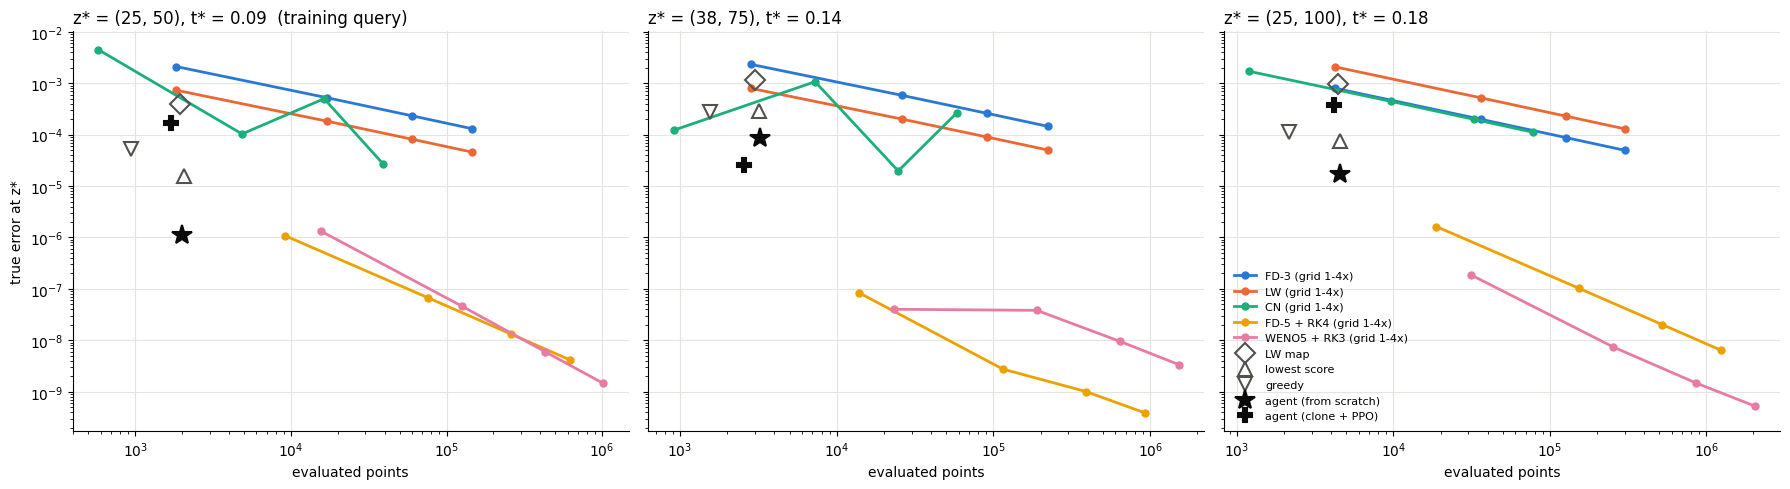

In [64]:
# ══ Comparison with classical solvers: true error at z* vs evaluated points ══
#   Classical schemes run on their own grids, refined k = 1..4 (r = alpha dt/dx^2 kept fixed), with the same boundary data
#   (inflow / outflow Dirichlet values g_left, g_right in time). Burgers: each grid point uses its own value as the speed.
#     FD-3: forward Euler + central 2nd order | LW: Lax-Wendroff | CN: Crank-Nicolson (speed from the previous step)
#     FD-5 + RK4: 4th-order central in space, RK4 in time | WENO5 + RK3: WENO5-JS (Lax-Friedrichs splitting) + SSP-RK3,
#     its ghost nodes past the walls taken from u_true (more data than the others get: this favours WENO).
#   Evaluated points = grid values computed in z*'s dependency cone (RK: x stages; CN: the whole row, it is implicit).
#   Map methods run on the base grid; they also pay for the guess levels up to t*. u_true ONLY for reporting (and WENO ghosts).
from scipy.linalg import solve_banded
from sb3_contrib import MaskablePPO
_gd = _gs.derivative()                                            # time derivative of the boundary data (RK stages)

def _weno5(vm2, vm1, v0, vp1, vp2):
    """WENO5-JS value at the interface on the vp1 side of v0."""
    q0, q1, q2 = (2 * vm2 - 7 * vm1 + 11 * v0) / 6, (-vm1 + 5 * v0 + 2 * vp1) / 6, (2 * v0 + 5 * vp1 - vp2) / 6
    b0 = 13 / 12 * (vm2 - 2 * vm1 + v0)**2 + 0.25 * (vm2 - 4 * vm1 + 3 * v0)**2
    b1 = 13 / 12 * (vm1 - 2 * v0 + vp1)**2 + 0.25 * (vm1 - vp1)**2
    b2 = 13 / 12 * (v0 - 2 * vp1 + vp2)**2 + 0.25 * (3 * v0 - 4 * vp1 + vp2)**2
    w0, w1, w2 = 0.1 / (1e-6 + b0)**2, 0.6 / (1e-6 + b1)**2, 0.3 / (1e-6 + b2)**2
    return (w0 * q0 + w1 * q1 + w2 * q2) / (w0 + w1 + w2)

def rhs(u, h, t, scheme):
    """du/dt at the nodes (walls: the time derivative of the boundary data)."""
    n = len(u)
    if scheme == "WENO5 + RK3":
        ue = np.r_[u_true(-h * np.arange(3, 0, -1), t), u, u_true(1 + h * np.arange(1, 4), t)]   # ue[j] = node j - 3
        am = np.abs(ue).max()
        fp, fm = 0.5 * (0.5 * ue**2 + am * ue), 0.5 * (0.5 * ue**2 - am * ue)
        j = np.arange(2, n + 3)
        F = _weno5(fp[j - 2], fp[j - 1], fp[j], fp[j + 1], fp[j + 2]) + _weno5(fm[j + 3], fm[j + 2], fm[j + 1], fm[j], fm[j - 1])
        c = np.arange(3, n + 3)
        du = -(F[1:] - F[:-1]) / h + alpha * (-ue[c + 2] + 16 * ue[c + 1] - 30 * ue[c] + 16 * ue[c - 1] - ue[c - 2]) / (12 * h**2)
    else:                                                          # FD-5: 4th-order central, 2nd order next to the walls
        u2, u1 = np.zeros(n), np.zeros(n)
        u2[1:-1], u1[1:-1] = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
        u2[2:-2] = (-u[4:] + 16 * u[3:-1] - 30 * u[2:-2] + 16 * u[1:-3] - u[:-4]) / 12
        u1[2:-2] = (-u[4:] + 8 * u[3:-1] - 8 * u[1:-3] + u[:-4]) / 12
        du = alpha * u2 / h**2 - u * u1 / h
    du[0], du[-1] = _gd(t)
    return du

def classical(scheme, k, z):
    """(evaluated points, true error at z*) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    t_star, ix = z[1] * dt, z[0] * k
    u = u0(np.arange(n) * h)
    if scheme == "WENO5 + RK3":                                    # its own stable step: CFL 0.4, diffusion number 0.2
        steps = int(np.ceil(t_star / min(0.4 * h / A_MAX, 0.2 * h**2 / alpha))); tau_k = t_star / steps
    else:
        tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2     # CN is implicit: 4x bigger steps
        steps = round(t_star / tau_k)
    r = alpha * tau_k / h**2
    for j in range(steps):
        t, t1 = j * tau_k, (j + 1) * tau_k
        if scheme == "WENO5 + RK3":
            u1 = u + tau_k * rhs(u, h, t, scheme)
            u2 = 0.75 * u + 0.25 * (u1 + tau_k * rhs(u1, h, t1, scheme))
            u = u / 3 + 2 / 3 * (u2 + tau_k * rhs(u2, h, t + tau_k / 2, scheme))
        elif scheme == "FD-5 + RK4":
            k1 = rhs(u, h, t, scheme); k2 = rhs(u + tau_k * k1 / 2, h, t + tau_k / 2, scheme)
            k3 = rhs(u + tau_k * k2 / 2, h, t + tau_k / 2, scheme); k4 = rhs(u + tau_k * k3, h, t1, scheme)
            u = u + tau_k * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            nu = u[1:-1] * tau_k / h
            d2, d1 = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
            new = u.copy()
            if scheme == "FD-3":
                new[1:-1] = u[1:-1] + r * d2 - nu * d1
            elif scheme == "LW":
                new[1:-1] = u[1:-1] + (r + nu**2 / 2) * d2 - nu * d1
            elif scheme == "CN":                                   # speed from the previous step (linearised CN)
                lo, up = -r / 2 - nu / 4, -r / 2 + nu / 4          # coefficients of u_{i-1}, u_{i+1} at the new time
                b = u[1:-1] + r / 2 * d2 - nu / 2 * d1
                b[0] -= lo[0] * g_left(t1); b[-1] -= up[-1] * g_right(t1)
                ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], 1 + r, lo[1:]
                new[1:-1] = solve_banded((1, 1), ab, b)
            new[0], new[-1] = g_left(t1), g_right(t1)
            u = new
    err = abs(u[ix] - Ug(z))
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8, "WENO5 + RK3": 9}.get(scheme)   # cone growth per step (RK: all stages)
    if spread is None:
        pts = (n - 2) * steps                                      # CN couples the whole row at every step
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        pts *= {"FD-5 + RK4": 4, "WENO5 + RK3": 3}.get(scheme, 1)
    return pts, err

# ── All methods at a few queries ──
SCHEMES = ["FD-3", "LW", "CN", "FD-5 + RK4", "WENO5 + RK3"]
Z_CMP   = [(25, 50), (38, 75), (25, 100)]                         # the training query and two unseen ones
AGENTS  = {"agent (from scratch)": ("inflow_smooth_scratch_gae0.97_z25-50_lam1-1", "ppo_final"),
           "agent (clone + PPO)":  ("inflow_smooth_imitation_z25-50_lam1", "ppo_final")}
agents  = {name: MaskablePPO.load(os.path.join("runs10-15", folder, "checkpoints", f), device="cpu") for name, (folder, f) in AGENTS.items()}
cmp = []
for z in Z_CMP:
    t0 = time.time()
    for scheme in SCHEMES:
        for k in (1, 2, 3, 4):
            pts, err = classical(scheme, k, z)
            cmp.append(dict(z=z, method=scheme, k=k, points=pts, error=err))
    guess_cost = (len(xc) - 2) * int(np.ceil(z[1] * dt / tau))     # guess levels up to t*, interior coarse points
    maps = {"LW map": build_map(z, lw), "lowest score": build_map(z, lowest_score), "greedy": build_map(z, greedy_rule(1.0))}
    maps.update({name: run_policy(model, z, 1.0).m for name, model in agents.items()})
    for name, m in maps.items():
        rep = report(m)
        cmp.append(dict(z=z, method=name, k=1, points=rep["points"] + guess_cost, error=rep["error"], bound=rep["bound"]))
    print(f"z* = {z}: {time.time() - t0:.0f} s (guess cost {guess_cost} points, added to every map method)")

# ── Table: each map method vs the classical schemes at the base grid (k = 1) ──
for z in Z_CMP:
    print(f"\nz* = {z}, t* = {z[1] * dt:.3f}")
    for c in cmp:
        if c["z"] == z and c["k"] == 1:
            extra = f" | bound {c['bound']:.1e}" if "bound" in c else ""
            print(f"  {c['method']:>22s}: {c['points']:7d} points | true error {c['error']:.1e}{extra}")

# ── Figure: true error vs evaluated points, one panel per query ──
COL = {"FD-3": "#5a92d8", "LW": "#eb6834", "CN": "#1baf7a", "FD-5 + RK4": "#eda100", "WENO5 + RK3": "#e87ba4"}
MK  = {"LW map": "D", "lowest score": "^", "greedy": "v", "agent (from scratch)": "*", "agent (clone + PPO)": "P"}
fig, axes = plt.subplots(1, len(Z_CMP), figsize=(6 * len(Z_CMP), 5), sharey=True)
for ax, z in zip(axes, Z_CMP):
    for s in SCHEMES:
        pts = sorted((c["points"], c["error"]) for c in cmp if c["z"] == z and c["method"] == s)
        ax.loglog(*zip(*pts), "o-", color=COL[s], lw=2, ms=5, label=f"{s} (grid 1-4x)")
    for name, mk in MK.items():
        c = next(c for c in cmp if c["z"] == z and c["method"] == name)
        ax.loglog(c["points"], c["error"], mk, color="#0b0b0b" if "agent" in name else "#52514e",
                  ms=15 if mk == "*" else 10, mfc="#0b0b0b" if "agent" in name else "none", mew=1.5, label=name)
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}" + ("  (training query)" if z == (25, 50) else ""), loc="left")
    ax.set_xlabel("evaluated points"); ax.grid(True, which="major", color="#e5e4df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("true error at z*"); axes[-1].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

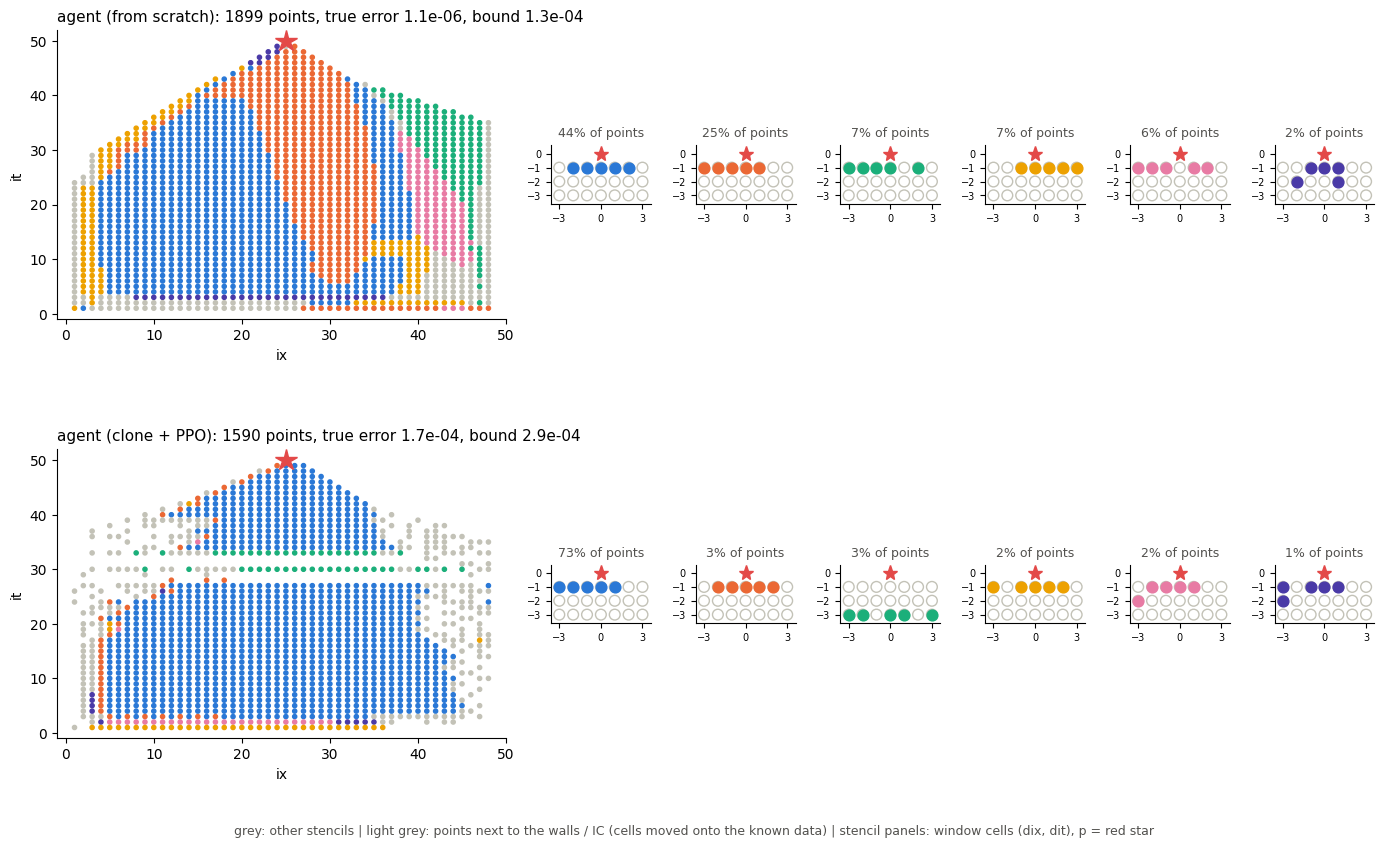

In [66]:
# ── Which stencil is used where: each agent's map at z*, every point coloured by its stencil (the 6 most used + other) ──
from collections import Counter
from sb3_contrib import MaskablePPO
Z_SHOW = (25, 50)
AGENTS = {"agent (from scratch)": ("inflow_smooth_scratch_gae0.97_z25-50_lam1-1", "ppo_final"),
          "agent (clone + PPO)":  ("inflow_smooth_imitation_z25-50_lam1", "ppo_final")}
TOP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
OTHER, EDGE = "#c3c2b7", "#e5e4df"                                # other stencils, points next to the walls / IC

def stencil_cells(p, nbs):
    """Window cells of p's stencil, or None next to the walls / IC (cells there are moved onto the known data)."""
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None

fig = plt.figure(figsize=(17, 4.6 * len(AGENTS)))
gs = fig.add_gridspec(len(AGENTS), 7, width_ratios=[4.5, 1, 1, 1, 1, 1, 1], hspace=0.45, wspace=0.3)
for row, (name, (folder, f)) in enumerate(AGENTS.items()):
    m = run_policy(MaskablePPO.load(os.path.join("runs10-15", folder, "checkpoints", f), device="cpu"), Z_SHOW, 1.0).m
    cells = {p: stencil_cells(p, nbs) for p, (nbs, w) in m["stencil"].items()}
    count = Counter(c for c in cells.values() if c is not None)
    top = [c for c, _ in count.most_common(6)]
    color = {c: TOP_COLORS[i] for i, c in enumerate(top)}
    rep = report(m)

    # the map: every computed point, coloured by its stencil
    ax = fig.add_subplot(gs[row, 0])
    P = np.array(list(cells))
    ax.scatter(P[:, 0], P[:, 1], s=9, c=[EDGE if c is None else color.get(c, OTHER) for c in cells.values()])
    ax.plot(*Z_SHOW, "*", color="#e34948", ms=16)
    ax.set_xlim(-1, nx); ax.set_ylim(-1, Z_SHOW[1] + 2); ax.set_xlabel("ix"); ax.set_ylabel("it")
    ax.set_title(f"{name}: {rep['points']} points, true error {rep['error']:.1e}, bound {rep['bound']:.1e}", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)

    # the 6 most used stencils, in the same colours
    total = sum(count.values())
    for i, c in enumerate(top):
        g = fig.add_subplot(gs[row, i + 1])
        g.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors=OTHER)
        g.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
        g.plot(0, 0, "*", color="#e34948", ms=11)
        g.set_xlim(-3.6, 3.6); g.set_ylim(-3.6, 0.6); g.set_aspect("equal")
        g.set_xticks([-3, 0, 3]); g.set_yticks([0, -1, -2, -3]); g.tick_params(labelsize=7)
        g.set_title(f"{count[c] / total:.0%} of points", fontsize=9, color="#52514e")
        g.spines[["top", "right"]].set_visible(False)
fig.text(0.5, 0.005, "grey: other stencils | light grey: points next to the walls / IC (cells moved onto the known data) | "
         "stencil panels: window cells (dix, dit), p = red star", ha="center", fontsize=9, color="#52514e")
plt.show()

### Videos and learning curves
From a finished run folder (no training here): the learning curves against the baselines, the training-progress video (the snapshot figures in order), and two build videos (the trained policy and Lax–Wendroff building their maps from $z^*$ down).

In [ ]:
# ── Load a finished run: paths, the settings used in training, and the trained model ──
import json
run_dir  = os.path.join("runs10-14", "inflow_smooth_scratch_z50-30_lam1-1")
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
with open(os.path.join(run_dir, "config.json")) as f:
    cfg = json.load(f)
EPS, Z_TRAIN, LAM_PLOT = cfg["eps"], tuple(cfg["queries"][0]), cfg["lam_range"][0]
print(f"run: {run_dir} | EPS = {EPS:.0e} | z* = {Z_TRAIN} | lam = {LAM_PLOT}")
model = MaskablePPO.load(os.path.join(ckpt_dir, "ppo_final"))

# ── What the evaluation cells need (normally defined in the scan / training cells) ──
def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])



def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

run: runs10-14\inflow_smooth_scratch_z50-30_lam1-1 | EPS = 1e-05 | z* = (50, 30) | lam = 1.0


**Front problem (α = 0.01), multi-query run `runs10-17/inflow_front_multi15_...`:** the agent stays at LW's level (it flattened after ~1M steps).
Cause: the score is fooled at the front. Lowest score and greedy get the best returns while their exact bound is 4–7× worse than LW's.
Open: fix the error estimate at fronts before training there.

## Findings so far (Oct 14–15, 2026)

**1. Old grid (nx = 100, z\* = (50, 30)): nothing to learn.** t\* = 0.014: the flow has moved ~1.4 cells and u has barely changed.
All trained policies ended at LW's bound (8–9.5e-5 vs 9.7e-5) with 1.8–2.2× LW's points.

**2. Why notebook 12 looked better: the "reach" feature.** Its state held the best score reachable through each cell, which means scoring all ~18.7k stencils (greedy's cost).
Removing it from the trained notebook-12 agent: bound 6.0e-5 → 1.3e-4 (LW: 1.4e-4); points stay ~240 (LW 400). Accuracy came from reach; saving points did not.

**3. New grid nx = 50, α = 0.1 (dt 4× larger): larger t\* matters.** By it\* = 50 (t\* = 0.09) u has changed by 43% of its amplitude and the flow has moved 7.5 cells.

**4. The guessed speed was hiding the gains.** At nx = 50, greedy / lowest score lost to LW at t\* ≥ 100 (their estimate ≈ 0, the score fooled).
Diagnosis at (25, 100) (exact values used only to diagnose): exact *speed* alone gives greedy a ~4× better bound; exact *derivatives* alone change nothing.
Fix, no oracle: the forward pass re-solves each point's weights with the speed of its own computed value (1 Picard step). Greedy: true error 8–14× below LW with 0.6–0.7× the points.

**5. Reward scale:** EPS 1e-5 → 1e-3, so LW's accuracy and points terms are both ~1 (as in notebook 12).

**6. First policy without score features that beats LW** (trained at (25, 50), 20M steps).
On 11 unseen queries (it\* = 30–100, ix\* = 12, 25, 38), relative to LW at the same query (median):
points ×1.08, **bound ×0.30**, **true error ×0.16**, better than LW on 10 of 11.
Its estimate is honest (B ≈ 2–3× its bound), unlike greedy / lowest score.

**7. But the gain is one stencil, not a per-point choice.** The agent uses 15 stencils; the top one (5 points in a row, one level down) covers 50% of the points.
That stencil used everywhere: bound ×0.27, error ×0.13: the same as the agent. The best fixed stencil (picked with the exact bound) also matches.
A fixed stencil picked by the *estimate* is much worse (bound ×0.89): the agent found a good scheme without an oracle, but did not show that adapting per point is needed.
All its frequent stencils use one level only: it never reaches further down, and never saves points.

**Open:** a problem where one fixed stencil cannot do well everywhere (next: a speed that changes sign), then the larger window.

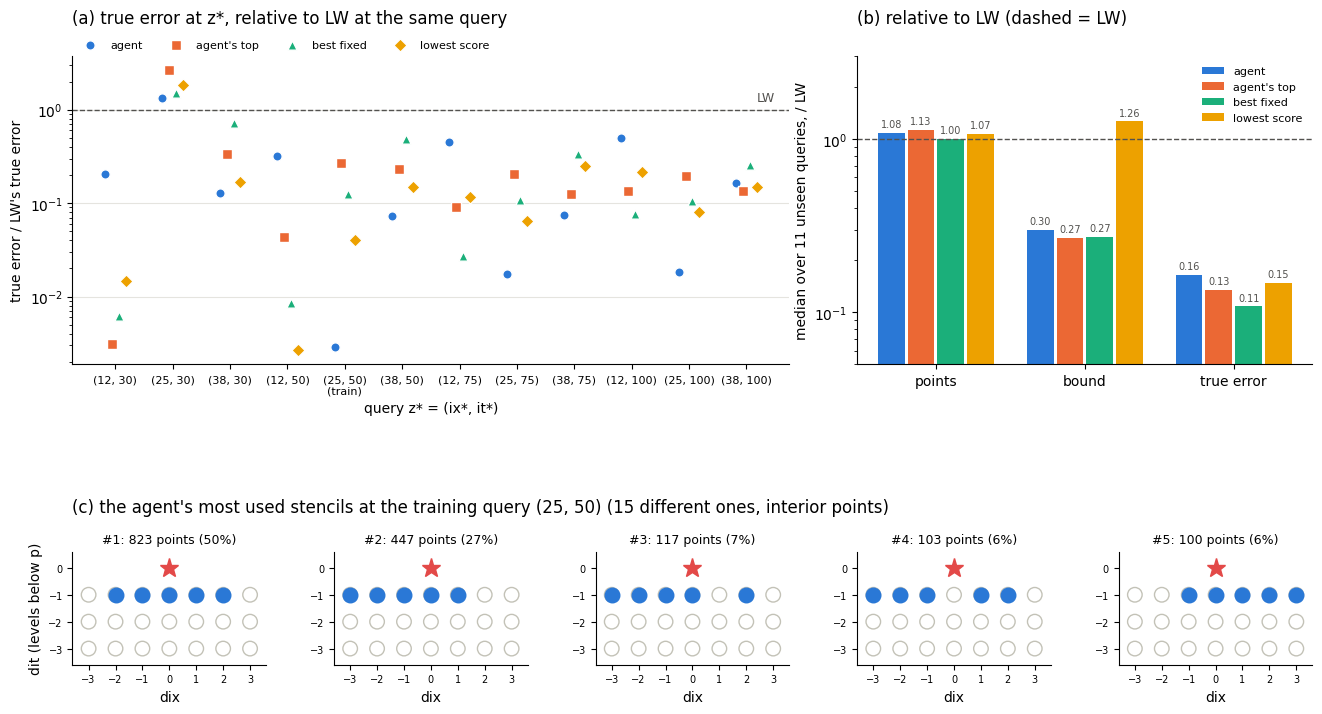

In [43]:
# ── Figure: Test 2 results (uses rows, used, QUERIES_TEST, Z_TRAIN from the Test 2 cell) ──
#   (a) true error of each method relative to LW, query by query (below 1 = better than LW)
#   (b) median over the unseen queries: points, bound and true error, each relative to LW
#   (c) the stencils the agent uses most at the training query (window cells, p = red star)
METHODS = ["agent", "agent's top", "best fixed", "lowest score"]
COLORS  = {"agent": "#2a78d6", "agent's top": "#eb6834", "best fixed": "#1baf7a", "lowest score": "#eda100"}
MARKERS = {"agent": "o", "agent's top": "s", "best fixed": "^", "lowest score": "D"}
get = lambda z, n: next(x for x in rows if x["z"] == z and x["method"] == n)
ratio = lambda z, n, k: get(z, n)[k] / get(z, "LW")[k]
unseen = [z for z in QUERIES_TEST if z != Z_TRAIN]

fig = plt.figure(figsize=(16, 8.5))
gs = fig.add_gridspec(2, 5, height_ratios=[1.5, 1], hspace=0.55, wspace=0.35)

# (a) per query
ax = fig.add_subplot(gs[0, :3])
xs = np.arange(len(QUERIES_TEST))
for j, n in enumerate(METHODS):
    ax.scatter(xs + (j - 1.5) * 0.12, [ratio(z, n, "error") for z in QUERIES_TEST], s=45, marker=MARKERS[n],
               color=COLORS[n], edgecolor="white", linewidth=1, label=n, zorder=3)
ax.axhline(1, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(len(QUERIES_TEST) - 0.5, 1.15, "LW", color="#52514e", ha="right", va="bottom", fontsize=9)
ax.set_yscale("log"); ax.set_xticks(xs)
ax.set_xticklabels([f"{z}\n(train)" if z == Z_TRAIN else str(z) for z in QUERIES_TEST], fontsize=8)
ax.set_xlabel("query z* = (ix*, it*)"); ax.set_ylabel("true error / LW's true error")
ax.set_title("(a) true error at z*, relative to LW at the same query", loc="left", pad=24)
ax.grid(axis="y", which="major", color="#e5e4df", lw=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)

# (b) medians over the unseen queries
ax = fig.add_subplot(gs[0, 3:])
keys = [("points", "points"), ("bound", "bound"), ("error", "true error")]
w = 0.2
for j, n in enumerate(METHODS):
    med = [np.median([ratio(z, n, k) for z in unseen]) for k, _ in keys]
    bars = ax.bar(np.arange(3) + (j - 1.5) * w, med, width=w - 0.02, color=COLORS[n], label=n)
    for b, v in zip(bars, med):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.05, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color="#52514e")
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_xticks(np.arange(3)); ax.set_xticklabels([l for _, l in keys])
ax.set_ylabel("median over 11 unseen queries, / LW"); ax.set_yscale("log"); ax.set_ylim(0.05, 3)
ax.set_title("(b) relative to LW (dashed = LW)", loc="left", pad=24)
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False, loc="upper right")

# (c) the agent's most used stencils
total = sum(used.values())
for i, (s, cnt) in enumerate(used.most_common(5)):
    ax = fig.add_subplot(gs[1, i])
    ax.scatter(*np.array(WINDOW).T, s=110, facecolors="none", edgecolors="#c3c2b7")
    ax.scatter(*np.array([WINDOW[k] for k in s]).T, s=110, color=COLORS["agent"])
    ax.plot(0, 0, "*", color="#e34948", ms=14)
    ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 0.6); ax.set_aspect("equal")
    ax.set_xticks(range(-3, 4)); ax.set_yticks([0, -1, -2, -3]); ax.tick_params(labelsize=7)
    ax.set_title(f"#{i + 1}: {cnt} points ({cnt / total:.0%})", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    if i == 0:
        ax.set_ylabel("dit (levels below p)")
        ax.text(0, 1.35, f"(c) the agent's most used stencils at the training query {Z_TRAIN} "
                f"({len(used)} different ones, interior points)", transform=ax.transAxes, fontsize=12)
    ax.set_xlabel("dix")
plt.show()